In [1]:
import glob
import pandas as pd
import matplotlib.pyplot as plt

H = 8760  # heures de l'année 2023

fichier_status = glob.glob("../data/raw/Status_Kelmarsh_1_*.csv")[0]
st = pd.read_csv(fichier_status, skiprows=9, na_values=["-"])
st.columns = [c.replace("# ", "", 1) for c in st.columns]
st["Timestamp start"] = pd.to_datetime(st["Timestamp start"])
st["Timestamp end"] = pd.to_datetime(st["Timestamp end"])
st["Duration"] = pd.to_timedelta(st["Duration"])

print(st.shape)
print(st["Status"].value_counts())

(7997, 11)
Status
Informational    7788
Stop              113
Warning            87
Communication       8
Curtailment         1
Name: count, dtype: int64


In [2]:
s = st.sort_values("Timestamp start").reset_index(drop=True).copy()

i = s[s["Status"] == "Informational"].copy()
i["fin"] = i["Timestamp start"].shift(-1)
i.loc[i.index[-1], "fin"] = pd.Timestamp("2024-01-01")
i["duree_h"] = (i["fin"] - i["Timestamp start"]).dt.total_seconds() / 3600
i["cat"] = i["IEC category"].fillna("Non classé")

etats = i.groupby("cat")["duree_h"].sum()
etats["Avant 1er événement (hypothèse)"] = (s["Timestamp start"].min() - pd.Timestamp("2023-01-01")).total_seconds() / 3600
tab_etats = pd.DataFrame({"heures": etats.round(1), "% année": (etats / H * 100).round(2)})
print(tab_etats.sort_values("heures", ascending=False).to_string())
print("Total :", tab_etats["% année"].sum().round(2), "%")

                                    heures  % année
cat                                                
Full Performance                    8496.5    96.99
Non classé                           101.1     1.15
Technical Standby                     74.4     0.85
Avant 1er événement (hypothèse)       74.4     0.85
Out of Environmental Specification    13.5     0.15
Total : 99.99 %


In [3]:
stops = s[s["Status"] == "Stop"].copy()
stops["h"] = stops["Duration"].dt.total_seconds() / 3600

strict = ["Forced outage", "Scheduled Maintenance", "Requested Shutdown"]

def dispo(cats):
    h = stops.loc[stops["IEC category"].isin(cats), "h"].sum()
    return round(h, 1), round((1 - h / H) * 100, 3)

print("Stricte               :", dispo(strict))
print("Stricte + givre       :", dispo(strict + ["Out of Environmental Specification"]))

f = stops[stops["IEC category"] == "Forced outage"]
print("Arrêts forcés :", len(f))
print("MTTR (min)    :", round(f["h"].mean() * 60, 1))
print("MTBF (h)      :", round((H - f["h"].sum()) / len(f)))

Stricte               : (np.float64(34.0), np.float64(99.611))
Stricte + givre       : (np.float64(85.7), np.float64(99.022))
Arrêts forcés : 10
MTTR (min)    : 3.6
MTBF (h)      : 876


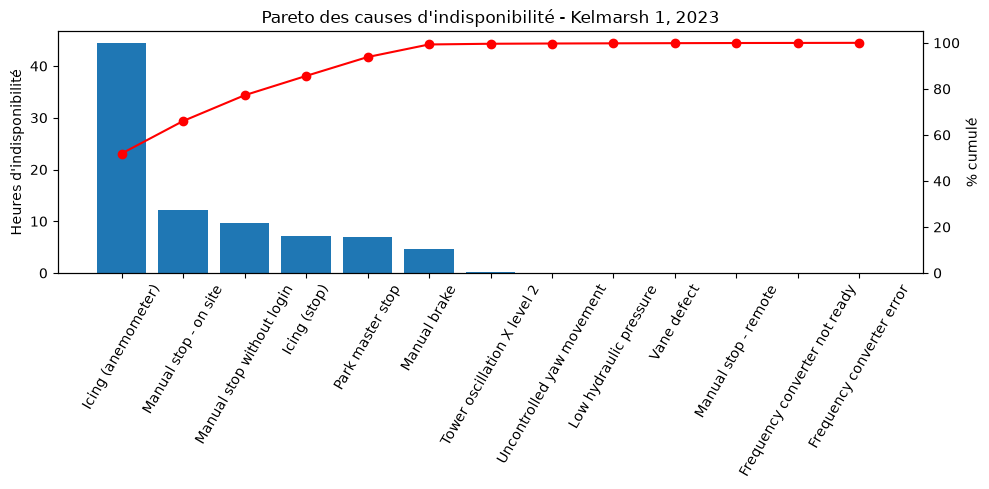

In [4]:
causes = stops[stops["IEC category"].isin(strict + ["Out of Environmental Specification"])]
par = causes.groupby("Message")["h"].sum().sort_values(ascending=False)
cum = par.cumsum() / par.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(par.index, par.values)
ax.set_ylabel("Heures d'indisponibilité")
ax.tick_params(axis="x", rotation=60)
ax2 = ax.twinx()
ax2.plot(par.index, cum.values, color="red", marker="o")
ax2.set_ylabel("% cumulé"); ax2.set_ylim(0, 105)
plt.title("Pareto des causes d'indisponibilité - Kelmarsh 1, 2023")
plt.tight_layout()
plt.savefig("j3_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

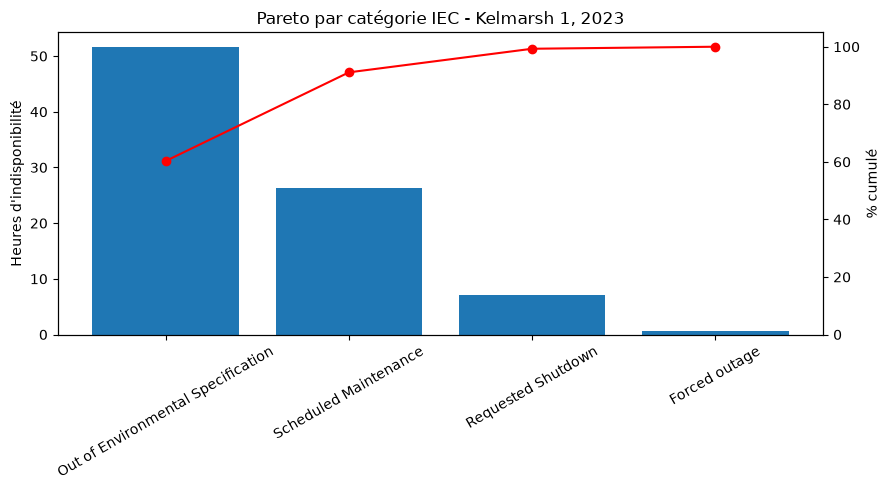

In [5]:
par_cat = causes.groupby("IEC category")["h"].sum().sort_values(ascending=False)
cum = par_cat.cumsum() / par_cat.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(par_cat.index, par_cat.values)
ax.set_ylabel("Heures d'indisponibilité")
ax.tick_params(axis="x", rotation=30)
ax2 = ax.twinx()
ax2.plot(par_cat.index, cum.values, color="red", marker="o")
ax2.set_ylabel("% cumulé"); ax2.set_ylim(0, 105)
plt.title("Pareto par catégorie IEC - Kelmarsh 1, 2023")
plt.tight_layout()
plt.savefig("j3_pareto_categorie.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
tab_etats.to_csv("j3_etats_pourcentage.csv")
par.round(1).to_csv("j3_causes_heures.csv")

In [7]:
debut, fin = pd.Timestamp("2023-08-10 05:40"), pd.Timestamp("2023-08-10 06:20")
ev = st[(st["Timestamp start"] >= debut) & (st["Timestamp start"] <= fin)]
print(ev[["Timestamp start", "Timestamp end", "Duration", "Status", "Code", "Message", "IEC category"]].to_string())

         Timestamp start       Timestamp end        Duration         Status    Code                Message       IEC category
4978 2023-08-10 06:00:00 2023-08-10 06:02:18 0 days 00:02:18           Stop     710           Battery test  Technical Standby
4979 2023-08-10 06:00:00                 NaT             NaT  Informational  100030      Brake program 180  Technical Standby
4980 2023-08-10 06:02:18                 NaT             NaT  Informational       0              System OK   Full Performance
4981 2023-08-10 06:02:18                 NaT             NaT  Informational  100110  Bypass limit switches   Full Performance
4982 2023-08-10 06:02:23                 NaT             NaT  Informational  100130     Automatic start-up   Full Performance
4983 2023-08-10 06:04:31                 NaT             NaT  Informational  100140          System test 1  Technical Standby
4984 2023-08-10 06:04:38                 NaT             NaT  Informational  100150          System test 2  Technical 

In [8]:
tests = st[(st["Status"] == "Stop") & (st["Message"].str.contains("Battery test"))]
dates_tests = set(tests["Timestamp start"].dt.floor("10min"))
sus = suspect.index  # lignes Cp < 0,3 du jour 2, si la variable existe encore
print(len(sus), sum(d in dates_tests for d in sus))

NameError: name 'suspect' is not defined

In [ ]:
df = pd.read_csv("kelmarsh1_2023_propre.csv", index_col=0, parse_dates=True)

trous = df["Power (kW)"].isna()
bloc = (trous != trous.shift()).cumsum()
g = trous.groupby(bloc)
b = pd.DataFrame({"trou": g.first(),
                  "debut": g.apply(lambda x: x.index[0]),
                  "fin": g.apply(lambda x: x.index[-1])})
print(b[b["trou"]][["debut", "fin"]].to_string())

print(st[st["Status"] == "Communication"][["Timestamp start", "Timestamp end"]].to_string())